# 03 · Modelado y evaluación

**Proyecto final · Machine Learning 1 · FIUNA (2026)**

**Objetivo:** comparar modelos que clasifican muestras de monitoreo de roya asiática de la soja (`y = 1` para la clase positiva) usando **10 predictores meteorológicos**, dos horizontes (`h0`, `h7`) y ventanas de 7 o 14 días.

Este notebook muestra **los datos usados, la validación temporal, la selección, el ajuste real de los modelos elegidos y sus resultados**. Las búsquedas completas ya ejecutadas se consultan desde `results/` para no volver a entrenar decenas de modelos en cada apertura.

> **Importante:** la evaluación denominada *histórica* corresponde a observaciones ya conocidas de enero-marzo de 2026; no constituye una validación prospectiva en producción.

## 1. Librerías y archivos del proyecto

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, precision_score, recall_score, accuracy_score,
                             balanced_accuracy_score, roc_auc_score, average_precision_score,
                             RocCurveDisplay, PrecisionRecallDisplay)

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'scripts/proyecto.json').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Abrí Jupyter desde la carpeta del proyecto o desde notebooks/.')
DATA = ROOT / 'data/processed'
RESULTS = ROOT / 'results'

with open(DATA / 'predictores.json', encoding='utf-8') as f:
    FEATURES = json.load(f)['features']
with open(DATA / 'particiones.json', encoding='utf-8') as f:
    PARTITIONS = json.load(f)
with open(RESULTS / 'seleccion.json', encoding='utf-8') as f:
    SELECTION = json.load(f)
with open(ROOT / 'scripts/proyecto.json', encoding='utf-8') as f:
    SETTINGS = json.load(f)['experimento']

comparison = pd.read_csv(RESULTS / 'comparacion.csv')
cv_scores = pd.read_csv(RESULTS / 'metricas.csv')
print('Predictores:', len(FEATURES))
print('Modelos seleccionados:', SELECTION['selected'])

Predictores: 10
Modelos seleccionados: {'0': 'RF_7d_h0', '7': 'LR_14d_h7'}


## 2. Variables de entrada y variable objetivo

Las entradas (`X`) son resúmenes meteorológicos previos a la fecha de referencia; la salida (`y`) es binaria. **No** se usan como predictores la fecha objetivo, la ubicación, los identificadores ni `resultado_t`.

- `h0`: clasificación de la etiqueta registrada en la fecha de referencia.
- `h7`: clasificación de la etiqueta exactamente siete días después.
- Una ventana de 7 o 14 días resume información climática previa, no posterior.

In [2]:
display(pd.DataFrame({'predictor': FEATURES}))

example = pd.read_csv(DATA / 'muestras_h0_7d.csv')
display(example[FEATURES + ['y']].head())
print('Valores faltantes en predictores:', int(example[FEATURES].isna().sum().sum()))
print('Distribución de clases (ejemplo h0, 7 días):')
display(example['y'].value_counts().sort_index().rename(index={0:'Negativa', 1:'Positiva'}))

,predictor
0,hr_media_pct
1,hr_min_pct
2,hr_max_pct
3,temperatura_media_c
4,temperatura_min_c
5,temperatura_max_c
6,precipitacion_mm
7,viento_vel_media_10m_ms
8,viento_u_media_10m_ms
9,viento_v_media_10m_ms


,hr_media_pct,hr_min_pct,hr_max_pct,temperatura_media_c,temperatura_min_c,temperatura_max_c,precipitacion_mm,viento_vel_media_10m_ms,viento_u_media_10m_ms,viento_v_media_10m_ms,y
0,67.613095,28.0,100.0,13.993452,-1.0,27.3,0.0,3.015655,-0.702679,-1.020719,0
1,70.023810,32.0,95.0,13.996429,-1.2,27.2,0.0,2.059583,-0.460562,-0.392832,0
2,65.827381,34.0,98.0,15.453571,1.7,28.5,0.0,2.454345,-0.575957,-0.565792,1
3,63.351190,34.0,100.0,14.732738,-0.2,27.1,0.0,2.916548,-0.945200,-0.818773,1
4,66.309524,26.0,98.0,15.054762,1.3,28.7,0.0,2.090655,-0.110576,-0.541432,0


Valores faltantes en predictores: 0
Distribución de clases (ejemplo h0, 7 días):


y
Negativa    217
Positiva    211
Name: count, dtype: int64

## 3. Separación temporal

Se mantienen los **tres folds de validación temporal** definidos en `data/processed/particiones.json`: cada uno utiliza fechas anteriores para entrenar y posteriores para validar. Hay una purga de 14 días antes del período validado para reducir el solapamiento y la contaminación temporal.

El período histórico de enero-marzo de 2026 se mantiene fuera de la selección de hiperparámetros. **No usamos una división aleatoria (`train_test_split`)**, porque aquí es fundamental respetar el orden temporal.

In [3]:
rows = []
for h in (0, 7):
    for fold in ('1', '2', '3', 'historico'):
        part = PARTITIONS[str(h)][fold]
        rows.append({'horizonte': f'h{h}', 'bloque': fold,
                     'entrenamiento': len(part['train_ids']),
                     'validacion': len(part['validation_ids']),
                     'purga': len(part['purged_ids']),
                     'inicio_validacion': part['fecha_inicio_referencia_validacion']})
display(pd.DataFrame(rows))

,horizonte,bloque,entrenamiento,validacion,purga,inicio_validacion
0,h0,1,164,38,2,2025-08-18
1,h0,2,188,55,16,2025-09-29
2,h0,3,239,100,20,2025-11-10
3,h0,historico,359,66,3,2026-01-05
4,h7,1,141,31,0,2025-08-11
5,h7,2,150,51,22,2025-09-22
6,h7,3,196,90,27,2025-11-03
7,h7,historico,313,46,3,2026-01-05


## 4. Modelos e hiperparámetros

Se compararon **regresión logística (LR)** y **Random Forest (RF)** sobre ventanas de 7 y 14 días, para cada horizonte: ocho configuraciones en total.

- **LR:** `StandardScaler` ajustado dentro de un `Pipeline` y regularización `C`.
- **RF:** 300 árboles; se evalúan profundidad máxima y mínimo de muestras por hoja.
- Las búsquedas originales emplearon `GridSearchCV`, F1 positivo y los tres folds temporales ya definidos. El escalado se ajusta exclusivamente con datos de entrenamiento.

La tabla siguiente procede de la búsqueda oficial guardada: no recalculamos ni optimizamos los hiperparámetros usando el período histórico.

In [4]:
configs = pd.DataFrame(SELECTION['configs'])
configs['seleccionado'] = configs.apply(
    lambda r: SELECTION['selected'][str(r['horizonte'])] == r['config'], axis=1)
display(configs[['config', 'modelo', 'horizonte', 'ventana', 'parametros',
                 'cv_f1', 'cv_std', 'seleccionado']].round(4))

print('Parámetros evaluados en la búsqueda:')
display(pd.DataFrame([
    {'modelo': 'LR', 'parámetro': 'C', 'valores': SETTINGS['lr_c']},
    {'modelo': 'RF', 'parámetro': 'max_depth', 'valores': SETTINGS['rf_max_depth']},
    {'modelo': 'RF', 'parámetro': 'min_samples_leaf', 'valores': SETTINGS['rf_min_samples_leaf']},
    {'modelo': 'RF', 'parámetro': 'n_estimators', 'valores': SETTINGS['rf_n_estimators']},
]))

,config,modelo,horizonte,ventana,parametros,cv_f1,cv_std,seleccionado
0,LR_7d_h0,LR,0,7,{'model__C': 0.1},0.6016,0.0722,False
1,RF_7d_h0,RF,0,7,"{'model__max_depth': 3, 'model__min_samples_le...",0.6289,0.1018,True
2,LR_14d_h0,LR,0,14,{'model__C': 10},0.6217,0.0262,False
3,RF_14d_h0,RF,0,14,"{'model__max_depth': 5, 'model__min_samples_le...",0.6159,0.0567,False
4,LR_7d_h7,LR,7,7,{'model__C': 1},0.5744,0.0830,False
5,RF_7d_h7,RF,7,7,"{'model__max_depth': None, 'model__min_samples...",0.5969,0.0956,False
6,LR_14d_h7,LR,7,14,{'model__C': 10},0.6312,0.0541,True
7,RF_14d_h7,RF,7,14,"{'model__max_depth': None, 'model__min_samples...",0.6143,0.0656,False


Parámetros evaluados en la búsqueda:


,modelo,parámetro,valores
0,LR,C,"[0.1, 1, 10]"
1,RF,max_depth,"[3, 5, None]"
2,RF,min_samples_leaf,"[3, 5, 10]"
3,RF,n_estimators,300


## 5. Resultados de validación y elección

La selección oficial usa **F1 medio de validación**. En caso de empate al redondear a tres decimales, se prioriza la ventana de 7 días y luego LR. El conjunto histórico no interviene en esta decisión.

fold,1,2,3
config,,,
LR_14d_h0,0.585,0.646,0.634
LR_14d_h7,0.595,0.708,0.591
LR_7d_h0,0.605,0.689,0.512
LR_7d_h7,0.486,0.686,0.551
RF_14d_h0,0.541,0.677,0.630
RF_14d_h7,0.606,0.698,0.538
RF_7d_h0,0.700,0.702,0.485
RF_7d_h7,0.571,0.725,0.495
mayoria_h0,0.566,0.000,0.000


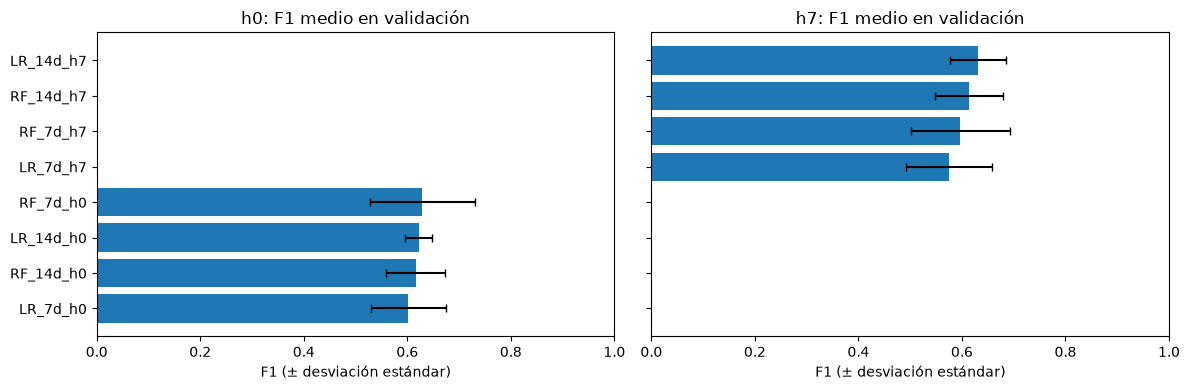

h0: RF_7d_h0 | F1 medio = 0.629 | parámetros: {'model__max_depth': 3, 'model__min_samples_leaf': 10}
h7: LR_14d_h7 | F1 medio = 0.631 | parámetros: {'model__C': 10}


In [5]:
validation = cv_scores[cv_scores['rol'] == 'validacion']
display(validation.pivot(index='config', columns='fold', values='f1').round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for h, ax in zip((0, 7), axes):
    part = configs[configs['horizonte'] == h].sort_values('cv_f1')
    ax.barh(part['config'], part['cv_f1'], xerr=part['cv_std'], capsize=3)
    ax.set(title=f'h{h}: F1 medio en validación', xlabel='F1 (± desviación estándar)', xlim=(0, 1))
plt.tight_layout()
plt.show()

for h in (0, 7):
    chosen = configs[configs['config'] == SELECTION['selected'][str(h)]].iloc[0]
    print(f"h{h}: {chosen['config']} | F1 medio = {chosen['cv_f1']:.3f} | parámetros: {chosen['parametros']}")

## 6. Entrenamiento de los modelos seleccionados

Ahora sí ejecutamos `fit()` y `predict_proba()` **en el notebook**, usando los hiperparámetros ya seleccionados y los IDs de entrenamiento del archivo de particiones.

El entrenamiento se realiza de nuevo **solo para mostrar y comprobar el procedimiento**; no reemplaza el experimento oficial ni guarda modelos sobre `models/`. Las predicciones históricas se usan solamente después del ajuste. Para obtenerlas se aplica el umbral fijo de **0,5**.

In [6]:
def construir_modelo(registro):
    parametros = registro['parametros']
    if registro['modelo'] == 'LR':
        return Pipeline([
            ('scale', StandardScaler()),
            ('model', LogisticRegression(C=parametros['model__C'],
                                         max_iter=SETTINGS['lr_max_iter'],
                                         random_state=SETTINGS['seed']))
        ])
    return Pipeline([
        ('model', RandomForestClassifier(
            n_estimators=SETTINGS['rf_n_estimators'],
            max_depth=parametros['model__max_depth'],
            min_samples_leaf=parametros['model__min_samples_leaf'],
            random_state=SETTINGS['seed'], n_jobs=1))
    ])

modelos = {}
predicciones = {}
resumen = []
for h in (0, 7):
    elegido = configs[configs['config'] == SELECTION['selected'][str(h)]].iloc[0]
    df = pd.read_csv(DATA / f"muestras_h{h}_{int(elegido['ventana'])}d.csv").set_index('muestra_id')
    ids = PARTITIONS[str(h)]['historico']
    train = df.loc[ids['train_ids']]
    test = df.loc[ids['validation_ids']]
    assert set(train.index).isdisjoint(test.index)
    assert pd.to_datetime(train['fecha_objetivo']).max() < pd.to_datetime(test['fecha_referencia']).min()
    assert train[FEATURES].notna().all().all() and test[FEATURES].notna().all().all()

    modelo = construir_modelo(elegido)
    modelo.fit(train[FEATURES], train['y'])
    prob = modelo.predict_proba(test[FEATURES])[:, 1]
    y_pred = (prob >= SETTINGS['threshold']).astype(int)

    modelos[h] = modelo
    predicciones[h] = {'y_real': test['y'].to_numpy(), 'y_pred': y_pred, 'prob': prob}
    resumen.append({'horizonte': f'h{h}', 'modelo': elegido['config'],
                    'n_train': len(train), 'n_historico': len(test),
                    'f1': f1_score(test['y'], y_pred, zero_division=0),
                    'precision': precision_score(test['y'], y_pred, zero_division=0),
                    'recall': recall_score(test['y'], y_pred, zero_division=0),
                    'accuracy': accuracy_score(test['y'], y_pred)})

display(pd.DataFrame(resumen).round(4))

,horizonte,modelo,n_train,n_historico,f1,precision,recall,accuracy
0,h0,RF_7d_h0,359,66,0.3846,0.6667,0.2703,0.5152
1,h7,LR_14d_h7,313,46,0.4848,0.8889,0.3333,0.6304


## 7. Comparación con los resultados oficiales

Comprobamos que el ajuste reproducido corresponde al mismo experimento registrado en `results/comparacion.csv`. Pequeñas diferencias pueden aparecer si cambian las versiones de librerías; no deben sustituirse silenciosamente los resultados oficiales.

In [7]:
for h in (0, 7):
    registro = comparison[comparison['config'] == SELECTION['selected'][str(h)]].iloc[0]
    p = predicciones[h]
    f1 = f1_score(p['y_real'], p['y_pred'], zero_division=0)
    matriz = confusion_matrix(p['y_real'], p['y_pred'], labels=[0, 1])
    matriz_oficial = np.array([[registro['historico_tn'], registro['historico_fp']],
                               [registro['historico_fn'], registro['historico_tp']]], dtype=int)
    print(f"h{h} | F1 notebook: {f1:.4f} | F1 oficial: {registro['historico_f1']:.4f}")
    print('Matriz reproducida:', matriz.ravel(), '| Matriz oficial:', matriz_oficial.ravel())
    assert np.array_equal(matriz, matriz_oficial), 'El ajuste no coincide con la evaluación oficial'
print('Las matrices reproducidas coinciden con los resultados oficiales.')

h0 | F1 notebook: 0.3846 | F1 oficial: 0.3846
Matriz reproducida: [24  5 27 10] | Matriz oficial: [24  5 27 10]
h7 | F1 notebook: 0.4848 | F1 oficial: 0.4848
Matriz reproducida: [21  1 16  8] | Matriz oficial: [21  1 16  8]
Las matrices reproducidas coinciden con los resultados oficiales.


## 8. Evaluación histórica: métricas y matrices de confusión

**Precisión** indica qué proporción de alertas positivas fue correcta; **recall** indica qué proporción de positivos reales detectamos; **F1** combina ambas. Debido al riesgo de omitir positivos, es importante interpretar el recall junto con F1 y no quedarse solamente con accuracy.

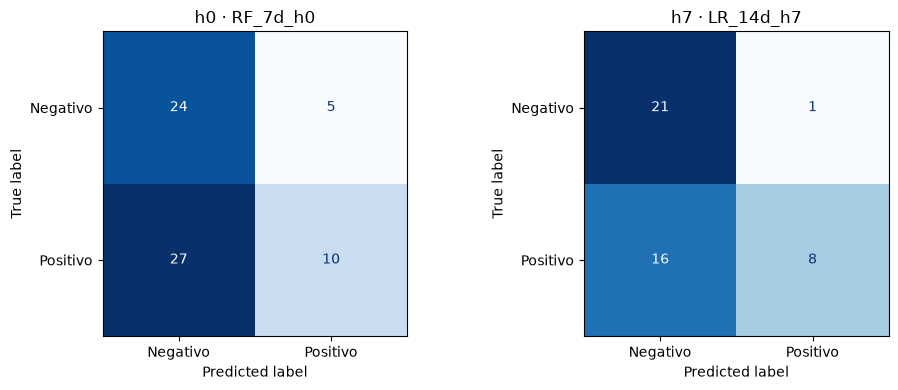

Clasificación histórica h0:
              precision    recall  f1-score   support

    Negativo       0.47      0.83      0.60        29
    Positivo       0.67      0.27      0.38        37

    accuracy                           0.52        66
   macro avg       0.57      0.55      0.49        66
weighted avg       0.58      0.52      0.48        66

Clasificación histórica h7:
              precision    recall  f1-score   support

    Negativo       0.57      0.95      0.71        22
    Positivo       0.89      0.33      0.48        24

    accuracy                           0.63        46
   macro avg       0.73      0.64      0.60        46
weighted avg       0.74      0.63      0.59        46



In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for h, ax in zip((0, 7), axes):
    p = predicciones[h]
    ConfusionMatrixDisplay.from_predictions(
        p['y_real'], p['y_pred'], labels=[0, 1],
        display_labels=['Negativo', 'Positivo'], cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(f'h{h} · {SELECTION["selected"][str(h)]}')
plt.tight_layout()
plt.show()

for h in (0, 7):
    p = predicciones[h]
    print(f'Clasificación histórica h{h}:')
    print(classification_report(p['y_real'], p['y_pred'],
                                labels=[0, 1], target_names=['Negativo','Positivo'],
                                zero_division=0))

## 9. Curvas ROC y Precision–Recall

Estas curvas utilizan las probabilidades calculadas tras el ajuste del modelo. **ROC AUC** mide la discriminación global; **average precision (AP)** resume el comportamiento de precisión y recall entre umbrales. No se eligió un nuevo umbral con el histórico.

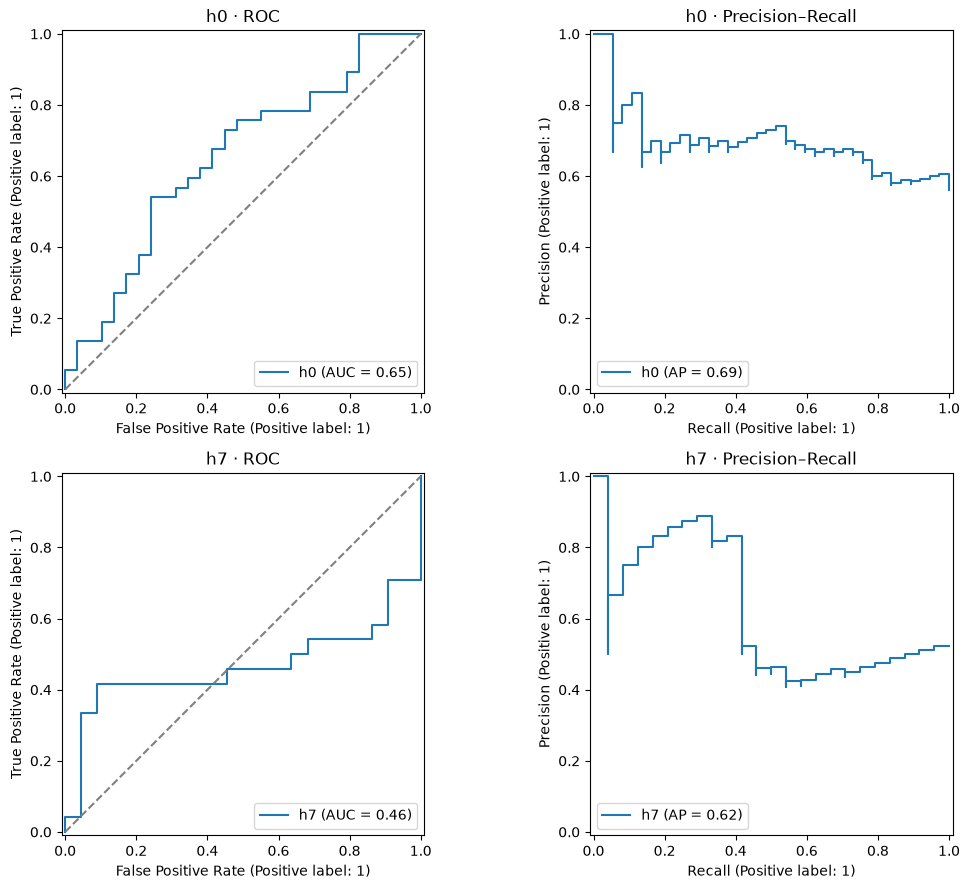

h0 | ROC AUC: 0.649 | AP: 0.695
h7 | ROC AUC: 0.464 | AP: 0.622


In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for fila, h in enumerate((0, 7)):
    p = predicciones[h]
    RocCurveDisplay.from_predictions(p['y_real'], p['prob'], ax=axes[fila, 0], name=f'h{h}')
    PrecisionRecallDisplay.from_predictions(p['y_real'], p['prob'], ax=axes[fila, 1], name=f'h{h}')
    axes[fila, 0].plot([0, 1], [0, 1], '--', color='gray')
    axes[fila, 0].set_title(f'h{h} · ROC')
    axes[fila, 1].set_title(f'h{h} · Precision–Recall')
plt.tight_layout()
plt.show()

for h in (0, 7):
    p = predicciones[h]
    print(f"h{h} | ROC AUC: {roc_auc_score(p['y_real'], p['prob']):.3f} | "
          f"AP: {average_precision_score(p['y_real'], p['prob']):.3f}")

## 10. Comparación con referencias simples

Una predicción debe compararse con métodos sencillos. El proyecto incluye la **clase mayoritaria** y, para h7, **persistencia** (usar el estado conocido en la fecha de referencia). Esta tabla proviene de la evaluación oficial y se presenta como referencia, no como un nuevo proceso de selección.

In [10]:
referencias = comparison[comparison['config'].str.startswith(('mayoria', 'persistencia'))]
elegidos = comparison[comparison['seleccionado'] == True]
columnas = ['config', 'historico_n', 'historico_f1', 'historico_precision', 'historico_recall']
display(pd.concat([elegidos, referencias])[columnas].round(3))

,config,historico_n,historico_f1,historico_precision,historico_recall
1,LR_14d_h7,46.0,0.485,0.889,0.333
6,RF_7d_h0,66.0,0.385,0.667,0.270
8,mayoria_h0,66.0,0.000,0.000,0.000
9,mayoria_h7,46.0,0.000,0.000,0.000
10,persistencia_h7,46.0,0.735,0.720,0.750


## 11. Conclusiones y limitaciones

- La selección mediante validación temporal favoreció **RF con ventana de 7 días para h0** y **LR con ventana de 14 días para h7**.
- La evaluación histórica se realizó en un período posterior a la selección, y muestra una caída notable del F1 positivo. Los resultados deben interpretarse como **evidencia exploratoria, no como un sistema de alerta validado**.
- El **recall positivo es bajo** en ambos modelos seleccionados; muchas observaciones positivas no reciben alerta con el umbral de 0,5.
- Las muestras históricas son reducidas y los dos horizontes no evalúan exactamente las mismas observaciones.
- Un trabajo futuro podría estudiar nuevas variables climáticas, calidad y cobertura de etiquetas, calibración y umbrales definidos exclusivamente sobre validación; cualquier cambio exige volver a evaluar con un período independiente.

**Reproducibilidad:** el código oficial de búsqueda exhaustiva y exportación de resultados está en `scripts/entrenar.py` y `scripts/evaluar.py`. Este notebook utiliza sus resultados guardados para mostrar las ocho configuraciones y reproduce el ajuste de los dos modelos elegidos, sin escribir en `results/` ni `models/`.

## 12. Experimento V2: variables de favorabilidad

Además de los diez predictores originales (V1), se evaluaron dos alternativas sobre las mismas muestras y particiones temporales:

- **V2-A:** cinco indicadores de favorabilidad meteorológica.
- **V2-B:** los diez predictores originales más los cinco indicadores nuevos.

Los modelos se seleccionaron usando exclusivamente validación temporal de desarrollo. El histórico sirve para la comparación final; no se ajustan variables, hiperparámetros ni umbrales después de observarlo. Esta sección lee resultados ya generados por los scripts, sin reentrenarlos.


,horizonte,experimento,config,cv_f1,f1,precision,recall,average_precision,tp,fn
0,0,V1,RF_7d_h0,0.6289,0.3846,0.6667,0.2703,0.6947,10,27
1,0,V2-A,favorabilidad_RF_14d_h0,0.6767,0.4074,0.6471,0.2973,0.7220,11,26
2,0,V2-B,combinadas_RF_14d_h0,0.6653,0.2500,0.5455,0.1622,0.7289,6,31
3,7,V1,LR_14d_h7,0.6312,0.4848,0.8889,0.3333,0.6225,8,16
4,7,V2-A,favorabilidad_RF_7d_h7,0.6358,0.4000,0.6364,0.2917,0.6342,7,17
5,7,V2-B,combinadas_RF_14d_h7,0.6403,0.2143,0.7500,0.1250,0.6487,3,21


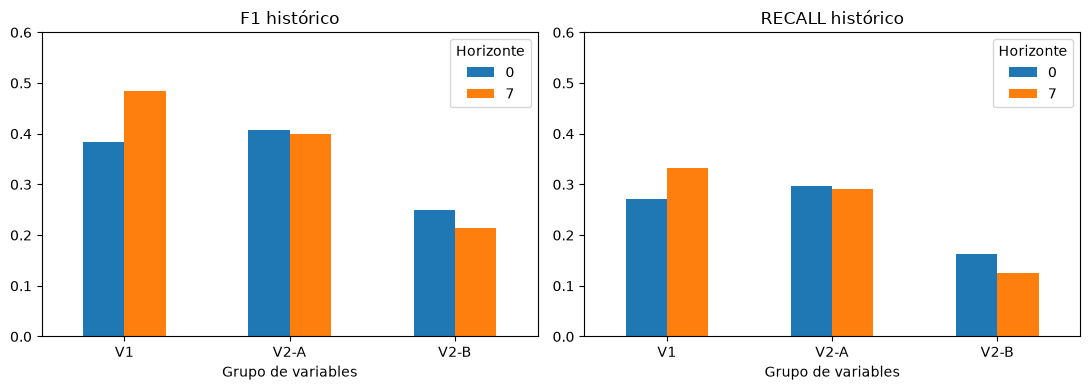

In [11]:
# Resultados experimentales V2: lectura y comparación reproducible
from IPython.display import display
import sys
sys.path.insert(0, str(ROOT / 'scripts'))
from evaluar import comparar_v1_v2

comparacion_v2 = comparar_v1_v2(v1_dir=ROOT / 'results')
columnas = ['horizonte', 'experimento', 'config', 'cv_f1', 'f1', 'precision', 'recall', 'average_precision', 'tp', 'fn']
display(comparacion_v2[columnas].round(4))

# F1 y recall en el histórico para h0 y h7
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metrica in zip(ejes, ('f1', 'recall')):
    comparacion_v2.pivot(index='experimento', columns='horizonte', values=metrica).plot.bar(ax=ax, rot=0)
    ax.set_title(f'{metrica.upper()} histórico')
    ax.set_ylim(0, 0.6)
    ax.set_xlabel('Grupo de variables')
    ax.legend(title='Horizonte')
plt.tight_layout()
plt.show()


### Conclusiones de V2

- **h0:** V2-A muestra una pequeña mejora del F1 histórico frente a V1, pero no una mejora general en ambos horizontes.
- **h7:** V1 supera a V2-A y V2-B en F1.
- **V2-B:** añadir todas las características no produjo una mejora; empeoró F1 y recall en el histórico.
- **Limitación:** el número de positivos detectados sigue siendo bajo. Además, las condiciones meteorológicas favorables son aproximaciones y no mediciones directas del mojado foliar.

**Decisión final:** conservar **V1 como versión principal del portal** y presentar V2 como experimento comparativo. No utilizar el histórico para seguir optimizando umbrales o seleccionando nuevas variables.
